# 07 - LSTM Baseline Model

## Objective
To develop an LSTM-based model for classifying multilingual
civic complaints into 12 predefined categories.

## Model Configuration
- Word2Vec pretrained embeddings
- Embedding dimension: 100
- LSTM units: 64
- Dropout: 0.3
- Output layer: 12 neurons with Softmax activation
- Optimizer: Adam
- Loss: Sparse Categorical Crossentropy

## Evaluation
- Training and validation accuracy
- Precision, Recall and F1-score
- Confusion Matrix
- Per-category classification performance

In [6]:
# Import libraries required for data loading and model development
import os
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Define the preprocessing directory
PREPROCESSING_DIR = "../models/preprocessing"

# Load the fitted tokenizer
with open(os.path.join(PREPROCESSING_DIR, "tokenizer.pkl"), "rb") as file:
    tokenizer = pickle.load(file)

# Load the fitted label encoder
with open(os.path.join(PREPROCESSING_DIR, "label_encoder.pkl"), "rb") as file:
    label_encoder = pickle.load(file)

# Load the maximum sequence length
MAX_LEN = int(np.load(os.path.join(PREPROCESSING_DIR, "max_len.npy")))

# Load the tokenized datasets
tokenized_data = np.load(
    os.path.join(PREPROCESSING_DIR, "tokenized_data.npz")
)

# Extract training, validation and test sequences
X_train = tokenized_data["X_train"]
X_val = tokenized_data["X_val"]
X_test = tokenized_data["X_test"]

# Extract encoded target labels
y_train = tokenized_data["y_train"]
y_val = tokenized_data["y_val"]
y_test = tokenized_data["y_test"]

# Load the saved Word2Vec embedding matrix
embedding_matrix = np.load(
    "../models/embeddings/word2vec_embedding_matrix.npy"
)

# Define model configuration
VOCAB_SIZE = embedding_matrix.shape[0]
EMBEDDING_DIM = embedding_matrix.shape[1]
NUM_CLASSES = len(label_encoder.classes_)

# Display dataset dimensions and configuration
print("Vocabulary Size:", VOCAB_SIZE)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Maximum Sequence Length:", MAX_LEN)
print("Number of Classes:", NUM_CLASSES)

print("\nTraining Shape:", X_train.shape, y_train.shape)
print("Validation Shape:", X_val.shape, y_val.shape)
print("Testing Shape:", X_test.shape, y_test.shape)

Vocabulary Size: 20089
Embedding Dimension: 100
Maximum Sequence Length: 156
Number of Classes: 12

Training Shape: (11563, 156) (11563,)
Validation Shape: (2478, 156) (2478,)
Testing Shape: (2478, 156) (2478,)


In [7]:
# Load the saved tokenized training, validation and test arrays
data = np.load("../models/preprocessing/tokenized_data.npz")

X_train_padded = data["X_train"]
X_val_padded = data["X_val"]
X_test_padded = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

In [8]:
# Import the layers required to build the LSTM classifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense

# Initialize the LSTM model using pretrained Word2Vec embeddings
lstm_model = Sequential([
    # Load the pretrained Word2Vec vectors into the embedding layer
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        mask_zero=True,
        trainable=True
    ),

    # Learn sequential patterns from complaint text
    LSTM(64),

    # Reduce overfitting during training
    Dropout(0.3),

    # Predict probabilities for the 12 complaint categories
    Dense(NUM_CLASSES, activation="softmax")
])

# Compile the model for multiclass classification
lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Explicitly build the model using the input sequence length
lstm_model.build(input_shape=(None, MAX_LEN))

# Display the model architecture and parameter counts
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 156, 100)       │     2,008,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,051,920 (7.83 MB)

 Trainable params: 2,051,920 (7.83 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Import EarlyStopping to prevent unnecessary training and reduce overfitting
from tensorflow.keras.callbacks import EarlyStopping

# Stop training when validation loss does not improve for 3 consecutive epochs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the LSTM model using the training data and monitor validation performance
history = lstm_model.fit(
    X_train_padded,
    y_train,
    validation_data=(X_val_padded, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - accuracy: 0.5670 - loss: 1.4497 - val_accuracy: 0.6929 - val_loss: 1.0207
Epoch 2/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 111ms/step - accuracy: 0.7531 - loss: 0.8757 - val_accuracy: 0.7546 - val_loss: 0.8571
Epoch 3/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.7979 - loss: 0.7353 - val_accuracy: 0.7893 - val_loss: 0.7576
Epoch 4/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 111ms/step - accuracy: 0.8365 - loss: 0.6020 - val_accuracy: 0.8010 - val_loss: 0.7163
Epoch 5/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - accuracy: 0.8557 - loss: 0.5266 - val_accuracy: 0.7990 - val_loss: 0.7000
Epoch 6/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 113ms/step - accuracy: 0.8835 - loss: 0.4397 - val_accuracy: 0.8099 - val_loss: 0.7134
Epoch 7/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.8919 - loss: 0.3991 - val_accuracy: 0.8152 - val_loss: 0.6769
Epoch 8/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.9043 - loss: 0

In [10]:
# Evaluate the restored best model on training and validation datasets
train_loss, train_accuracy = lstm_model.evaluate(
    X_train_padded, y_train, verbose=0
)

val_loss, val_accuracy = lstm_model.evaluate(
    X_val_padded, y_val, verbose=0
)

# Display the final metrics using the restored best weights
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Training Loss: {train_loss:.4f}")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

Training Accuracy: 0.9077
Training Loss: 0.3328
Validation Accuracy: 0.8152
Validation Loss: 0.6769


In [11]:
# Import the classification report and prediction utilities
from sklearn.metrics import classification_report
import numpy as np

# Generate class probabilities for the validation dataset
y_val_prob = lstm_model.predict(X_val_padded)

# Convert predicted probabilities into class labels
y_val_pred = np.argmax(y_val_prob, axis=1)

# Generate a category-wise precision, recall and F1-score report
print(classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
))

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
                                       precision    recall  f1-score   support

                    Animal Management     0.9752    0.9077    0.9402       130
Civic Infrastructure and Encroachment     0.2917    0.3889    0.3333        36
                Drainage and Sewerage     0.6387    0.5033    0.5630       151
            Electricity and Utilities     0.7857    0.8049    0.7952        41
        Environment and Public Spaces     0.5923    0.6754    0.6311       114
                        Public Safety     0.3333    0.0333    0.0606        30
                    Public Sanitation     0.8906    0.7917    0.8382        72
                  Road Infrastructure     0.8268    0.8584    0.8423       784
                      Street Lighting     0.9630    0.8235    0.8878       221
                Traffic and Transport     0.6634    0.7816    0.7177       174
                     Waste Management     0.8765    0.8945    0.8854       635
           

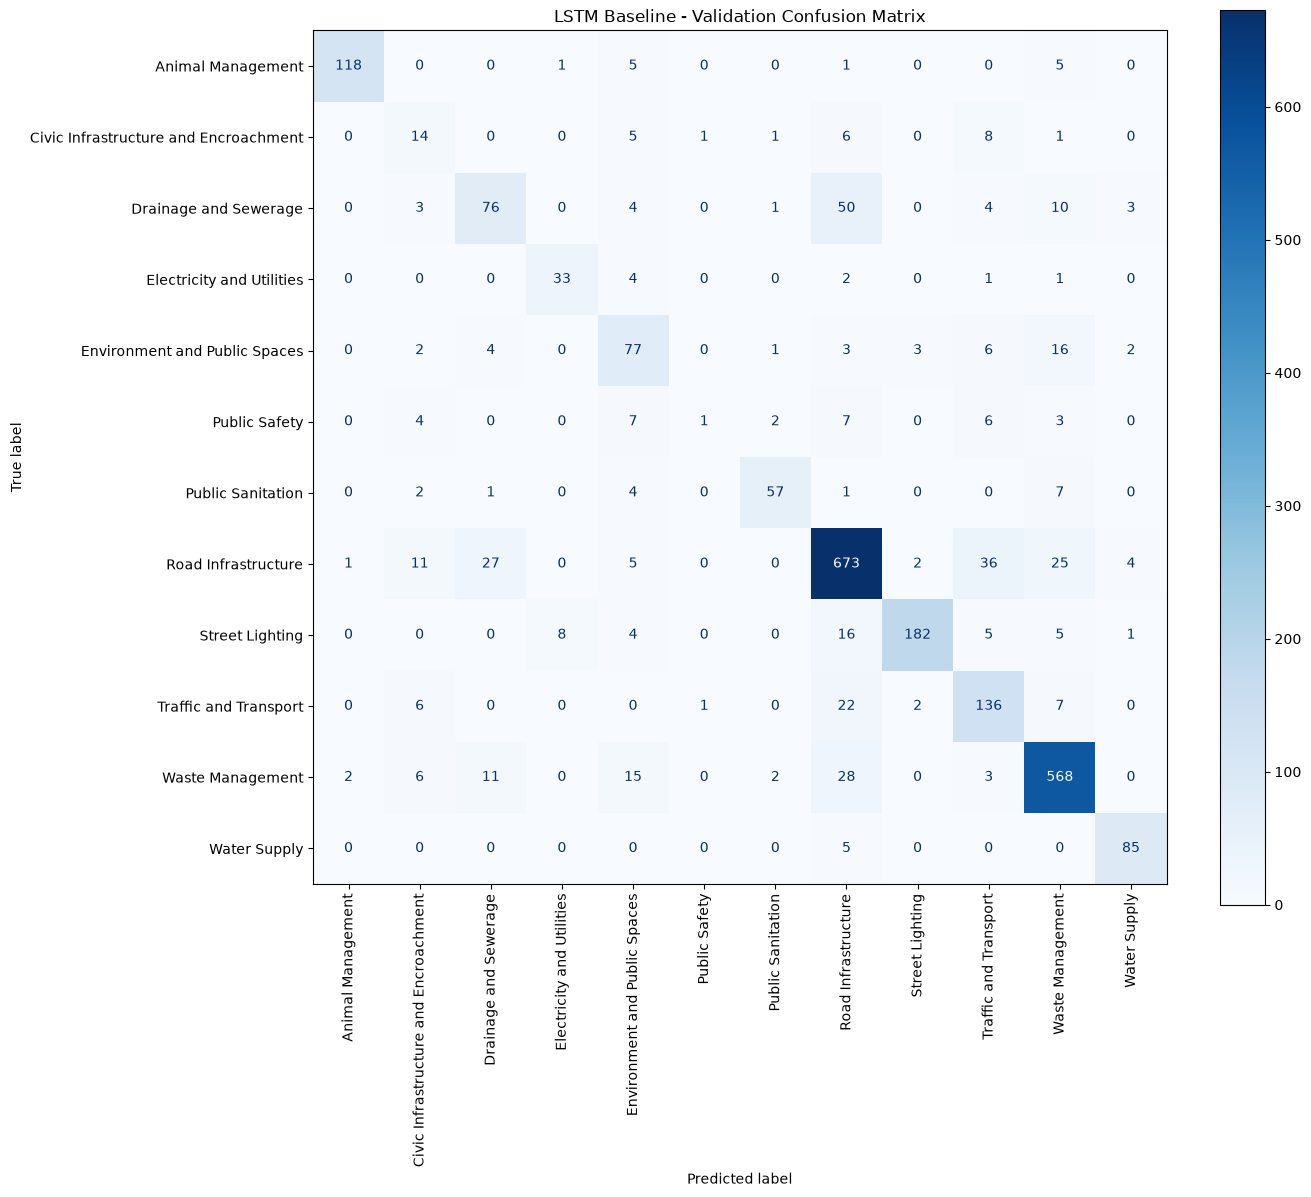

In [12]:
# Import confusion matrix utilities
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix using validation predictions
cm = confusion_matrix(y_val, y_val_pred)

# Create a labelled confusion matrix for all 12 categories
plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

# Display counts with rotated category labels
disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    ax=plt.gca()
)

plt.title("LSTM Baseline - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
# Import the required libraries for saving model results
import os
import pandas as pd

# Create a dedicated directory for the LSTM baseline experiment
save_dir = "../models/experiments/lstm_baseline"
os.makedirs(save_dir, exist_ok=True)

# Save the trained LSTM model with its restored best weights
lstm_model.save(
    os.path.join(save_dir, "lstm_baseline_word2vec.keras")
)

# Save training and validation metrics for future comparison
history_df = pd.DataFrame(history.history)
history_df.to_csv(
    os.path.join(save_dir, "training_history.csv"),
    index=False
)

# Save the validation classification report
report = classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(save_dir, "validation_classification_report.csv")
)

# Confirm the saved experiment files
print("LSTM baseline experiment saved successfully.")
print(os.listdir(save_dir))

LSTM baseline experiment saved successfully.
['lstm_baseline_word2vec.keras', 'training_history.csv', 'validation_classification_report.csv']


In [14]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Generate predictions on the untouched test dataset
y_test_prob = lstm_model.predict(X_test_padded)
y_test_pred = np.argmax(y_test_prob, axis=1)

# Calculate overall test-set performance
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
test_recall = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

# Display the final test metrics
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall: {test_recall:.4f}")
print(f"Macro F1-score: {test_f1:.4f}")
print(f"Weighted F1-score: {test_weighted_f1:.4f}")

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step
Test Accuracy: 0.8192
Macro Precision: 0.7197
Macro Recall: 0.6964
Macro F1-score: 0.6977
Weighted F1-score: 0.8158


In [15]:
# Import pandas and os for saving the evaluation results
import pandas as pd
import os

# Create a dictionary containing all test evaluation metrics
test_results = {
    "Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Weighted F1-score"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_weighted_f1
    ]
}

# Convert the results into a DataFrame
test_results_df = pd.DataFrame(test_results)

# Save the test results in the existing LSTM experiment folder
test_results_df.to_csv(
    "../models/experiments/lstm_baseline/test_results.csv",
    index=False
)

# Confirm that the results have been saved
print("Test evaluation results saved successfully!")
print(test_results_df)

Test evaluation results saved successfully!
              Metric     Score
0      Test Accuracy  0.819209
1    Macro Precision  0.719668
2       Macro Recall  0.696357
3     Macro F1-score  0.697694
4  Weighted F1-score  0.815803
